# Adiabatic CZ Gate Simulation in cQED

This notebook demonstrates the physics of a flux-tunable Controlled-Z (CZ) gate using two capacitively coupled transmon qutrits.

By adiabatically tuning the magnetic flux $\Phi_{\text{ext}}(t)$ of one transmon, we bring the computational state $|11\rangle$ into resonance with the non-computational state $|02\rangle$. A carefully shaped flat-top pulse allows the system to accumulate a $\pi$ phase (yielding a $-1$ multiplier) while minimizing leakage.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from cz_simulator import TransmonCZSimulator

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.grid'] = True

## 1. System Initialization

We initialize the `TransmonCZSimulator` with standard hardware parameters. The class will automatically build the required QuTiP operators and the 9-dimensional Hamiltonians in both the Lab and Rotating frames.

In [2]:
# Initialize simulator with default parameters
sim = TransmonCZSimulator(
    Ec1=0.3, Ej1=11.7, 
    Ec2=0.3, Ej2=13.5, 
    g=0.015
)

print(f"Plasma Frequency Qubit 1: {sim.omega1:.4f} GHz")
print(f"Plasma Frequency Qubit 2: {sim.omega2:.4f} GHz")
print(f"Theoretical Target Flux (Phi/Phi0): {sim.phi_target:.4f}")
print(f"Square Pulse Analytical Time: {sim.t_gate_square:.2f} ns")

Plasma Frequency Qubit 1: 5.2991 GHz
Plasma Frequency Qubit 2: 5.6921 GHz
Theoretical Target Flux (Phi/Phi0): 0.0813
Square Pulse Analytical Time: 148.10 ns


## 2. Energy Spectrum & Avoided Crossing

To realize the gate, we rely on the avoided crossing between $|11\rangle$ and $|02\rangle$. Let's plot the energy levels in the Lab Frame as a function of the external magnetic flux to visualize this phenomenon.

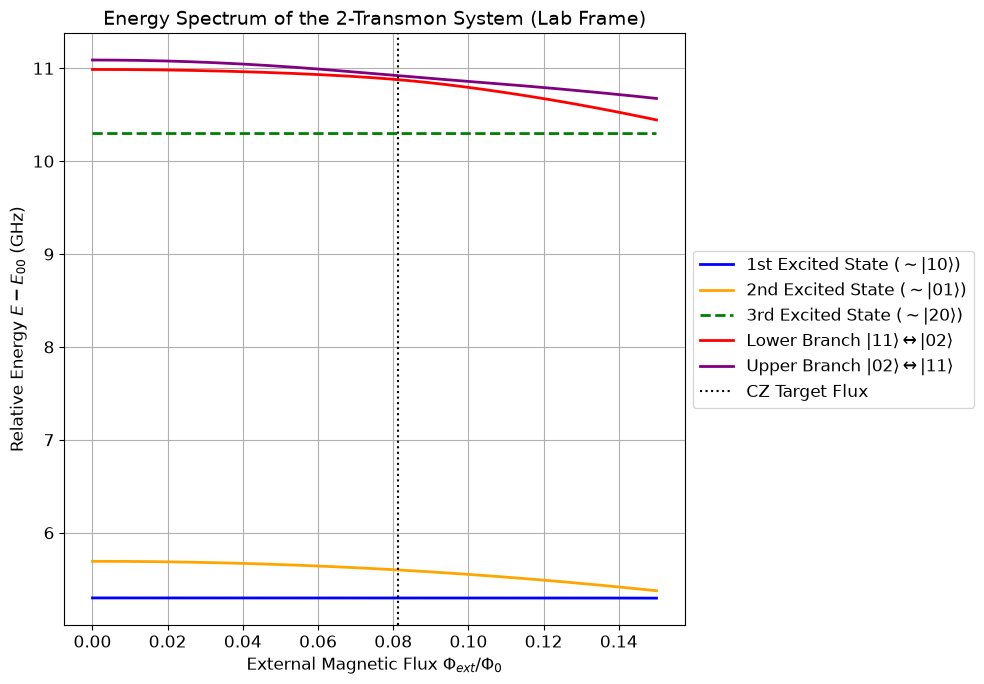

In [3]:
phi_array, energies = sim.compute_spectrum(phi_max=0.15, num_points=300)

plt.figure(figsize=(10, 7))

plt.plot(phi_array, energies[:, 1], label=r'1st Excited State ($\sim |10\rangle$)', color='blue', lw=2)
plt.plot(phi_array, energies[:, 2], label=r'2nd Excited State ($\sim |01\rangle$)', color='orange', lw=2)
plt.plot(phi_array, energies[:, 3], label=r'3rd Excited State ($\sim |20\rangle$)', color='green', linestyle='--', lw=2)

# The avoided crossing is isolated between the 4th and 5th excited states
plt.plot(phi_array, energies[:, 4], label=r'Lower Branch $|11\rangle \leftrightarrow |02\rangle$', color='red', lw=2)
plt.plot(phi_array, energies[:, 5], label=r'Upper Branch $|02\rangle \leftrightarrow |11\rangle$', color='purple', lw=2)

plt.axvline(sim.phi_target, color='black', linestyle=':', label='CZ Target Flux')

plt.title("Energy Spectrum of the 2-Transmon System (Lab Frame)", fontsize=14)
plt.xlabel(r"External Magnetic Flux $\Phi_{ext} / \Phi_0$", fontsize=12)
plt.ylabel(r"Relative Energy $E - E_{00}$ (GHz)", fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True)
plt.tight_layout()
plt.show()

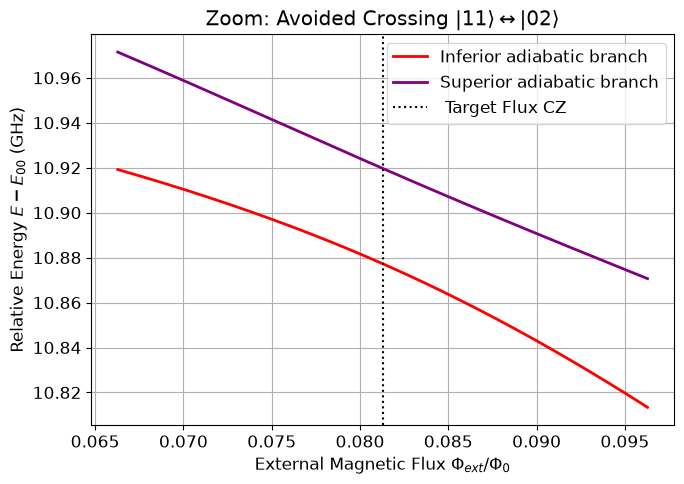

In [4]:
phi_center = sim.phi_target
phi_zoom = np.linspace(phi_center - 0.015, phi_center + 0.015, 200)
energies_adiabatic = np.zeros((200, sim.dim**2))

for i, phi in enumerate(phi_zoom):
    u = np.sqrt(np.cos(np.pi * phi))
    H_tot = sim.H_0_lab + u * sim.H_u
    evals = H_tot.eigenenergies()
    energies_adiabatic[i, :] = evals - evals[0]

plt.figure(figsize=(7, 5))
# I livelli coinvolti nell'avoided crossing sono il 4° e il 5° eccitato
plt.plot(phi_zoom, energies_adiabatic[:, 4], color='red', lw=2, label="Inferior adiabatic branch")
plt.plot(phi_zoom, energies_adiabatic[:, 5], color='purple', lw=2, label="Superior adiabatic branch")
plt.axvline(phi_center, color='black', linestyle=':', label=" Target Flux CZ")

plt.title("Zoom: Avoided Crossing $|11\\rangle \leftrightarrow |02\\rangle$")
plt.xlabel(r"External Magnetic Flux $\Phi_{ext} / \Phi_0$")
plt.ylabel(r"Relative Energy $E - E_{00}$ (GHz)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 3. Pulse Dynamics: 1D Sweep

Instead of a hard square pulse, we use a smooth flat-top pulse to satisfy adiabaticity limits and prevent diabatic transitions. Because the flux does not reach its maximum value instantly, the ideal gate time $T$ will be slightly longer than the analytical square-pulse time.

Let's sweep the total gate time $T$ at a fixed ramp time $\sigma$.

Scanning T from 100.0 ns to 200.0 ns...


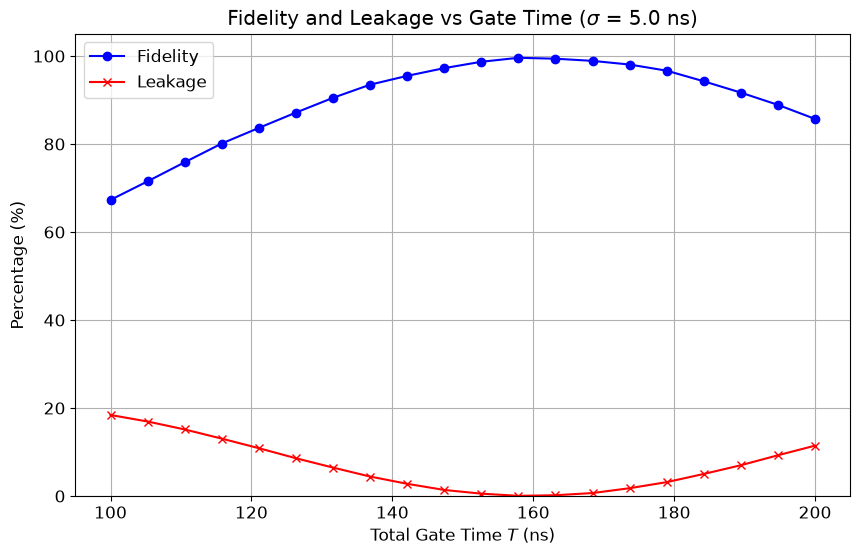

In [6]:
T_list = np.linspace(100, 200, 20)
sigma_fixed = 5.0

fidelities = []
leakages = []

print(f"Scanning T from {T_list[0]:.1f} ns to {T_list[-1]:.1f} ns...")
for T in T_list:
    fid, leak = sim.evaluate_pulse(T, sigma_fixed)
    fidelities.append(fid)
    leakages.append(leak)

plt.figure()
plt.plot(T_list, fidelities, label='Fidelity', color='blue', marker='o')
plt.plot(T_list, leakages, label='Leakage', color='red', marker='x')
plt.xlabel('Total Gate Time $T$ (ns)')
plt.ylabel('Percentage (%)')
plt.title(f'Fidelity and Leakage vs Gate Time ($\sigma$ = {sigma_fixed} ns)')
plt.ylim(0, 105)
plt.legend()
plt.show()

## 4. Automated Pulse Optimization

Finding the absolute best parameters by hand via 1D or 2D sweeps is computationally expensive and prone to precision errors. 

Instead, we can use our built-in Nelder-Mead optimizer. It actively explores the parameter space for $T$, $\sigma$, and optionally the pulse amplitude (`amp`) to compensate for AC Stark shifts and finite-duration effects, automatically maximizing the Gate Fidelity.

In [7]:
print("Starting Nelder-Mead optimization (this may take a minute)...")

# We allow a 15% tolerance on the amplitude for fine-tuning
opt_results = sim.optimize_pulse(
    sigma_bounds=(4.0, 15.0),
    T_bounds=(None, 250.0),
    amp_tol=0.15
)

print("\n--- Optimization Complete ---")
print(f"Optimal Gate Time (T) : {opt_results['T_opt']:.2f} ns")
print(f"Optimal Ramp (sigma)  : {opt_results['sigma_opt']:.2f} ns")
print(f"Optimal Amplitude     : {opt_results['amp_opt']:.4f}")
print(f"Max Gate Fidelity     : {opt_results['fidelity']:.4f} %")
print(f"Residual Leakage      : {opt_results['leakage']:.4f} %")

Starting Nelder-Mead optimization (this may take a minute)...

--- Optimization Complete ---
Optimal Gate Time (T) : 175.37 ns
Optimal Ramp (sigma)  : 6.74 ns
Optimal Amplitude     : 0.0818
Max Gate Fidelity     : 99.9878 %
Residual Leakage      : 0.0060 %


## 5. Automated Pulse Optimization via CLI

For hardware calibration routines or batch processing on an HPC cluster, you can bypass the Python API and use the provided Command-Line Interface (CLI). The `optimize_pulse.py` script accepts physical transmon parameters as arguments and automatically runs the Nelder-Mead optimization to find the optimal gate time $T$, ramp time $\sigma$, and flux amplitude.

Below is an example of calling the CLI directly from the notebook, simulating a slightly asymmetric transmon pair.

In [ ]:
# Run the CLI optimizer with custom hardware parameters
!python optimize_pulse.py --Ec1 0.29 --Ej1 12.7 --Ec2 0.30 --Ej2 14.2 --g 0.018 --sigma-min 5.0 --sigma-max 10.0 --ampl-tol 0.15

=== Initializing Transmon Qutrit CZ Simulator ===
Plasma Frequency Qubit 1 (omega_p1): 5.4281 GHz
Plasma Frequency Qubit 2 (omega_p2): 5.8378 GHz
Theoretical Target Flux (Phi/Phi0): 0.0831
Square Pulse Analytical Time (T)  : 123.41 ns

Running Nelder-Mead optimization over (T, sigma, amp) with ±15% amplitude bounds...

=== Optimization Results ===
Optimal Gate Duration (T)    : 136.92 ns
Optimal Ramp Time (sigma)    : 5.04 ns
Optimal Flux Amplitude (amp) : 0.0841
Max Gate Fidelity            : 99.9684 %
Residual Leakage             : 0.0166 %


c:\Users\nunzi\Desktop\GITHUB_PROJECTS\transmon-cz-gate-simulation\.venv\Lib\site-packages\qutip\core\coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)
